# Domestic Flight Price Prediction — 01 · Exploratory Data Analysis

**Goal:** predict the ticket `price` of a domestic flight booking from its attributes. Models are evaluated by **Root Mean Squared Error (RMSE)** on the raw price, so large absolute errors on expensive tickets dominate the score.

This notebook covers the dataset and the EDA (report sections 2–3). Run the notebooks in order:

| Notebook | Content |
|---|---|
| **01_EDA** | dataset, target, missing values, markets, airlines, booking curve, duration and stops, fare spikes, noise floor, travel-date effects, duplicates |
| 02_Preprocessing | airline recovery, duration imputation, encoding and scaling, feature engineering, leak tests, ablation |
| 03_Models | basic models, advanced models, tuning, final ensemble, training-size experiment |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# chart style: validated colour-blind-safe palette, hairline grids
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK2, MUTED, GRID, BASE = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False, "lines.linewidth": 2, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left"})
kfmt = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}K" if abs(v) >= 1000 else f"{v:,.0f}")

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (15589, 12) | test: (3898, 11)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


## 1. Dataset overview

We were provided with three files: `train.csv` (features + target `price`), `test.csv` (features only) and `sample_submission.csv` (`id`, `price`).

In [2]:
overview = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "unique values": train.nunique(),
    "missing in train": train.isna().sum(),
    "missing in test": test.isna().sum().reindex(train.columns),
})
overview

,dtype,unique values,missing in train,missing in test
id,int64,15589,0,0.0
airline,object,18,3089,799.0
flight,object,1070,0,0.0
source_city,object,6,0,0.0
departure_time,object,6,0,0.0
stops,object,3,0,0.0
arrival_time,object,6,0,0.0
destination_city,object,6,0,0.0
flight_class,object,2,0,0.0
duration,float64,243,3095,776.0


## 2. Target variable

`price` is a continuous, strongly right-skewed fare. It is really two distributions: Economy and Business.

In [3]:
y = train["price"]
print(y.describe().round(0).to_string())
print(f"\nskewness: {y.skew():.2f}")
by_class = train.groupby("flight_class")["price"].agg(["size", "mean", "median", "min", "max"]).round(0)
display(by_class)
print(f"Business fares average {by_class.loc['Business', 'mean'] / by_class.loc['Economy', 'mean']:.1f}x Economy")

count     15589.0
mean      29817.0
std       39128.0
min        3801.0
25%        7210.0
50%       10183.0
75%       35968.0
max      323177.0

skewness: 2.70


,size,mean,median,min,max
flight_class,,,,,
Business,6380,60127.0,38546.0,15544,323177
Economy,9209,8818.0,7587.0,3801,74691


Business fares average 6.8x Economy


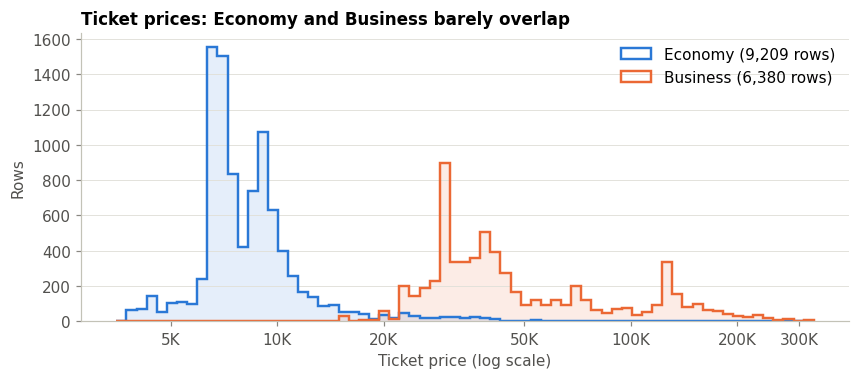

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.logspace(np.log10(3500), np.log10(330000), 70)
for cls, col in (("Economy", BLUE), ("Business", ORANGE)):
    v = train.loc[train["flight_class"] == cls, "price"]
    ax.hist(v, bins=bins, histtype="stepfilled", color=col, alpha=0.12)
    ax.hist(v, bins=bins, histtype="step", color=col, linewidth=1.6, label=f"{cls} ({len(v):,} rows)")
ax.set_xscale("log")
ax.set_xticks([5000, 10000, 20000, 50000, 100000, 200000, 300000])
ax.xaxis.set_major_formatter(kfmt)
ax.minorticks_off()
ax.set_xlabel("Ticket price (log scale)")
ax.set_ylabel("Rows")
ax.grid(axis="y")
ax.legend()
ax.set_title("Ticket prices: Economy and Business barely overlap")
plt.show()

## 3. Missing values

Only `airline` and `duration` have gaps (about 20% each, in both files). They are blanked independently of each other.

In [5]:
miss = pd.DataFrame({"missing in train": train.isna().sum(), "% train": 100 * train.isna().mean(),
                     "missing in test": test.isna().sum(), "% test": 100 * test.isna().mean()})
display(miss[miss["missing in train"] > 0].round(1))
print(pd.crosstab(train["airline"].isna().rename("airline missing"),
                  train["duration"].isna().rename("duration missing")))
print(f"\ntraining rows with at least one gap: {(train['airline'].isna() | train['duration'].isna()).mean():.1%}")

,missing in train,% train,missing in test,% test
airline,3089,19.8,799.0,20.5
duration,3095,19.9,776.0,19.9


duration missing  False  True 
airline missing               
False             10007   2493
True               2487    602



training rows with at least one gap: 35.8%


Dropping rows is not an option: more than a third of the rows have a gap, and the test file has the same gaps, so every test row still needs a prediction. Both columns turn out to be recoverable (see 02_Preprocessing).

## 4. Airlines and foreign carriers

The first token of `flight` (e.g. `AI` in `AI 2641`) is the airline's IATA code.

In [6]:
for df in (train, test):
    df["flight_prefix"] = df["flight"].str.split().str[0]
both = pd.concat([train, test], ignore_index=True)
known = both.dropna(subset=["airline"])
purity = known.groupby("flight_prefix")["airline"].nunique()
print(f"{len(purity)} flight prefixes; every one maps to exactly one airline: {bool((purity == 1).all())}")

FOREIGN = {"EK", "EY", "QR", "SQ", "TG", "UL", "MH", "WY", "GF", "KU", "FZ", "RA"}   # foreign carriers' IATA codes
prefix_of = train.dropna(subset=["airline"]).groupby("airline")["flight_prefix"].first()
print(f"{prefix_of.isin(FOREIGN).sum()} of the {len(prefix_of)} airlines in the training data are foreign carriers")

# airline recovered from the prefix (02_Preprocessing) for the chart below
prefix_map = known.groupby("flight_prefix")["airline"].agg(lambda s: s.mode()[0])
train["airline_full"] = train["airline"].fillna(train["flight_prefix"].map(prefix_map))
train["is_foreign"] = train["flight_prefix"].isin(FOREIGN)

20 flight prefixes; every one maps to exactly one airline: True
12 of the 18 airlines in the training data are foreign carriers


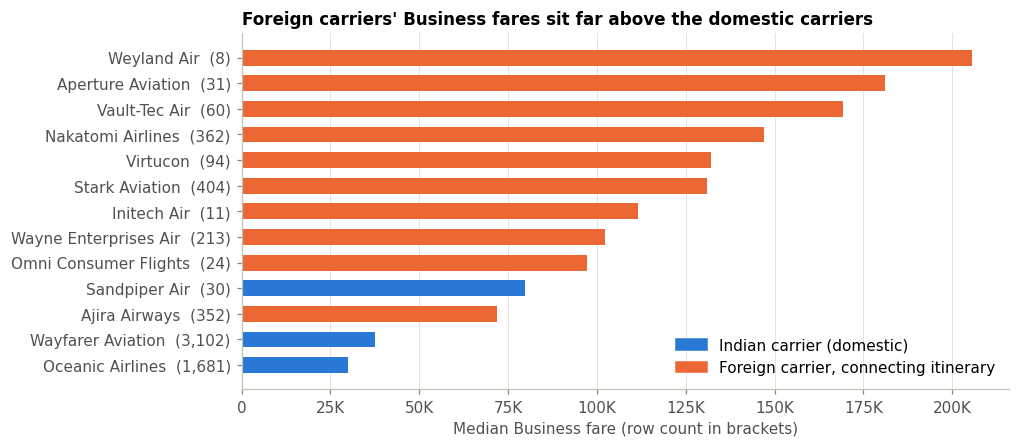

In [7]:
b = train[train["flight_class"] == "Business"]
g = b.groupby(["airline_full", "is_foreign"])["price"].agg(["median", "size"]).reset_index()
g = g[g["size"] >= 8].sort_values("median")
fig, ax = plt.subplots(figsize=(9, 4.2))
yy = np.arange(len(g))
ax.barh(yy, g["median"], height=0.62, color=[ORANGE if f else BLUE for f in g["is_foreign"]])
ax.set_yticks(yy, [f"{a}  ({n:,})" for a, n in zip(g["airline_full"], g["size"])])
ax.xaxis.set_major_formatter(kfmt)
ax.grid(axis="x")
ax.set_axisbelow(True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Indian carrier (domestic)"),
                   Patch(color=ORANGE, label="Foreign carrier, connecting itinerary")], loc="lower right")
ax.set_xlabel("Median Business fare (row count in brackets)")
ax.set_title("Foreign carriers' Business fares sit far above the domestic carriers")
plt.show()

## 5. The booking curve and Simpson's paradox

corr(days_left, price) over all rows: -0.023


days_left,1-3,4-7,8-14,15-30,31+
flight_class,,,,,
Business,48562.0,41124.0,43234.0,38129.0,37771.0
Economy,9099.0,7463.0,7716.0,7473.0,7435.0


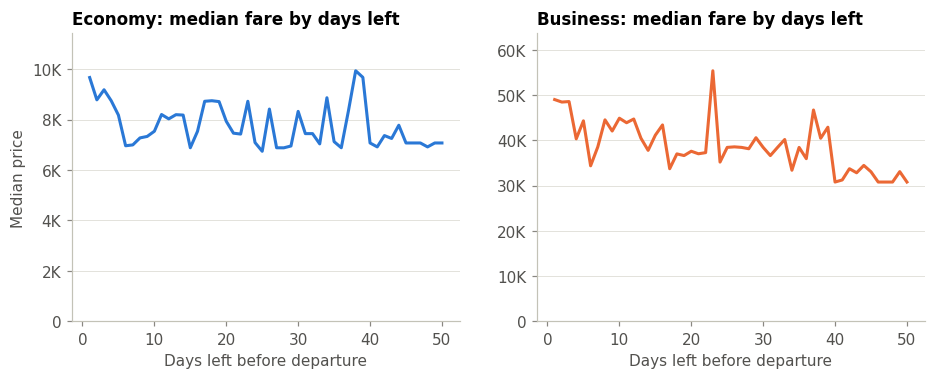

In [8]:
print(f"corr(days_left, price) over all rows: {train['days_left'].corr(train['price']):+.3f}")
buckets = pd.cut(train["days_left"], [0, 3, 7, 14, 30, 60], labels=["1-3", "4-7", "8-14", "15-30", "31+"])
display(train.groupby(["flight_class", buckets], observed=True)["price"].median().unstack().round(0))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, cls, col in ((axes[0], "Economy", BLUE), (axes[1], "Business", ORANGE)):
    s = train[(train["flight_class"] == cls) & (train["days_left"] <= 50)]
    m = s.groupby("days_left")["price"].median()
    ax.plot(m.index, m.values, color=col)
    ax.set_title(f"{cls}: median fare by days left")
    ax.yaxis.set_major_formatter(kfmt)
    ax.set_ylim(0, m.max() * 1.15)
    ax.grid(axis="y")
    ax.set_xlabel("Days left before departure")
axes[0].set_ylabel("Median price")
plt.show()

Overall, `days_left` looks useless (correlation about −0.02). Within each cabin, however, fares clearly rise in the last few days. The overall correlation is masked because the Economy/Business mix changes with `days_left`: a textbook **Simpson's paradox**.

## 6. Duration, stops and time slots

corr(duration, price) = 0.70  ->  R² ≈ 0.49 from duration alone


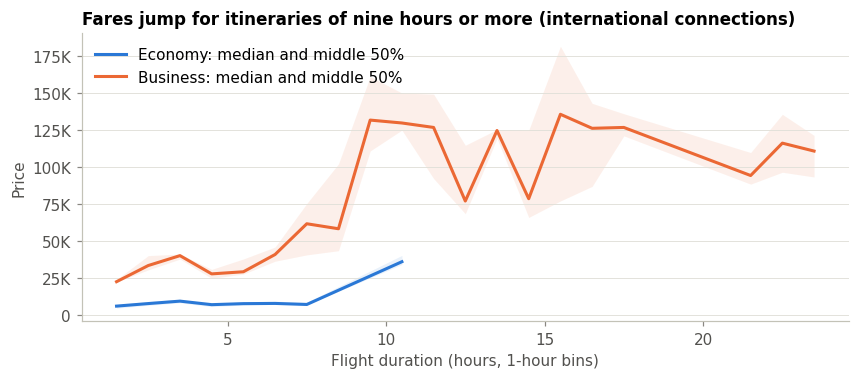

In [9]:
obs = train["duration"].notna()
r = train.loc[obs, "duration"].corr(train.loc[obs, "price"])
print(f"corr(duration, price) = {r:.2f}  ->  R² ≈ {r * r:.2f} from duration alone")

fig, ax = plt.subplots(figsize=(9, 3.4))
for cls, col in (("Economy", BLUE), ("Business", ORANGE)):
    s = train[(train["flight_class"] == cls) & obs & (train["duration"] <= 30)]
    gg = s.groupby(np.floor(s["duration"]))["price"]
    ok = gg.size() >= 15
    med, q1, q3 = gg.median()[ok], gg.quantile(0.25)[ok], gg.quantile(0.75)[ok]
    ax.fill_between(med.index + 0.5, q1, q3, color=col, alpha=0.10, linewidth=0)
    ax.plot(med.index + 0.5, med.values, color=col, label=f"{cls}: median and middle 50%")
ax.yaxis.set_major_formatter(kfmt)
ax.grid(axis="y")
ax.set_xlabel("Flight duration (hours, 1-hour bins)")
ax.set_ylabel("Price")
ax.legend(loc="upper left")
ax.set_title("Fares jump for itineraries of nine hours or more (international connections)")
plt.show()

In [10]:
display(train.groupby("stops")["price"].agg(["size", "median"]).reindex(["zero", "one", "two_or_more"]).round(0))
display(pd.DataFrame({"median by departure slot": train.groupby("departure_time")["price"].median(),
                      "median by arrival slot": train.groupby("arrival_time")["price"].median()})
        .sort_values("median by departure slot", ascending=False).round(0))

,size,median
stops,,
zero,10965,8883.0
one,4558,40528.0
two_or_more,66,125611.0


,median by departure slot,median by arrival slot
Late_Night,33067.0,17180.0
Night,11000.0,11466.0
Morning,10864.0,9883.0
Early_Morning,9943.0,9181.0
Afternoon,9802.0,9846.0
Evening,9450.0,10045.0


## 7. Fare buckets, random spikes and the noise floor

An **itinerary** is a flight number flown on one route with one stop count and one pair of time slots. Prices behave like fare buckets: one itinerary repeats the same fare on most days and occasionally jumps to two or three times that.

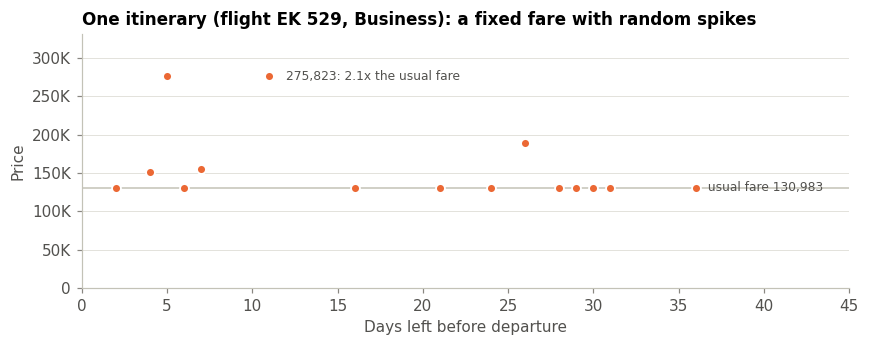

rows (in itineraries with 3+ rows) priced exactly at their itinerary's most common fare: 54%


In [11]:
ITIN = ["flight", "source_city", "destination_city", "stops", "departure_time", "arrival_time"]
train["itin_c"] = train[ITIN + ["flight_class"]].astype(str).agg("|".join, axis=1)

ex = train[(train["flight"] == "EK 529") & (train["flight_class"] == "Business")
           & (train["destination_city"] == "Springfield") & (train["arrival_time"] == "Morning")].sort_values("days_left")
usual = ex["price"].median()
fig, ax = plt.subplots(figsize=(9, 3.0))
ax.axhline(usual, color=BASE, linewidth=1)
ax.scatter(ex["days_left"], ex["price"], s=34, color=ORANGE, edgecolor="white", linewidth=1.2, zorder=3)
ax.text(ex["days_left"].max() + 0.5, usual, f" usual fare {usual:,.0f}", va="center", color=INK2, fontsize=8)
spikes = ex[ex["price"] > 1.8 * usual]
ax.text(spikes["days_left"].max() + 1, spikes["price"].max(),
        f"{spikes['price'].max():,.0f}: {spikes['price'].max() / usual:.1f}x the usual fare", va="center", color=INK2, fontsize=8)
ax.yaxis.set_major_formatter(kfmt)
ax.set_ylim(0, ex["price"].max() * 1.2)
ax.set_xlim(0, ex["days_left"].max() + 9)
ax.grid(axis="y")
ax.set_xlabel("Days left before departure")
ax.set_ylabel("Price")
ax.set_title("One itinerary (flight EK 529, Business): a fixed fare with random spikes")
plt.show()

grp = train.groupby("itin_c")["price"]
multi = grp.transform("size") >= 3
mode_share = (train.loc[multi, "price"] == grp.transform(lambda s: s.mode().iloc[0])[multi]).mean()
print(f"rows (in itineraries with 3+ rows) priced exactly at their itinerary's most common fare: {mode_share:.0%}")

Nothing in the columns predicts these jumps, so they act as noise. How low could any model go? If every itinerary's true mean price were known, the remaining error would be the spread **within** itineraries:

In [12]:
import flight_pipeline as fp                        # the cleaned duration from 02_Preprocessing
train["duration_filled"] = fp.load_clean()[0]["duration"].to_numpy()[:len(train)]

def noise_floor(keys):
    g = train.groupby(keys)["price"]
    ss = ((train["price"] - g.transform("mean")) ** 2).sum()
    return np.sqrt(ss / (len(train) - g.ngroups))   # pooled within-group standard deviation

print(f"knowing each itinerary x cabin mean:            RMSE floor ≈ {noise_floor(['itin_c']):,.0f}")
print(f"... and splitting by duration as well:          RMSE floor ≈ {noise_floor(['itin_c', 'duration_filled']):,.0f}")

knowing each itinerary x cabin mean:            RMSE floor ≈ 9,490
... and splitting by duration as well:          RMSE floor ≈ 9,339


So roughly **9,000–9,500 RMSE** is the floor for any model that only learns itinerary averages; only effects *within* an itinerary (the booking curve, travel-date effects) can go below it.

## 8. Where the price spread lives

,share of rows,share of price spread within segments
segment,,
Economy,59.1,4.0
Domestic Business,30.9,30.9
Foreign Business,10.1,65.1


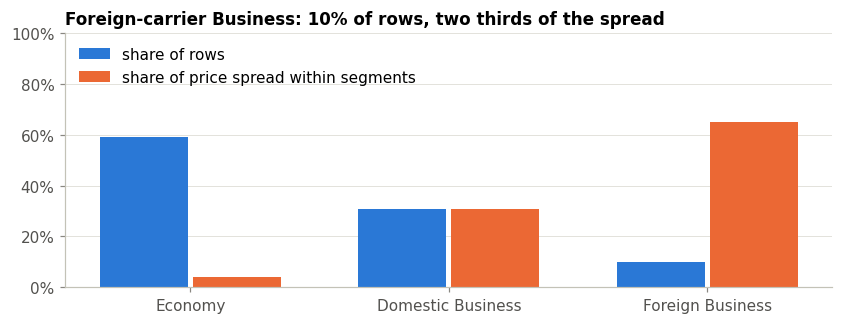

In [13]:
train["segment"] = np.where(train["flight_class"] == "Economy", "Economy",
                            np.where(train["is_foreign"], "Foreign Business", "Domestic Business"))
segs = ["Economy", "Domestic Business", "Foreign Business"]
spread = train.groupby("segment")["price"].transform(lambda s: (s - s.mean()) ** 2)
table = pd.DataFrame({"share of rows": train["segment"].value_counts(normalize=True),
                      "share of price spread within segments": spread.groupby(train["segment"]).sum() / spread.sum()}).loc[segs]
display((100 * table).round(1))

fig, ax = plt.subplots(figsize=(9, 3.0))
x = np.arange(3)
for i, (col, c) in enumerate(zip(table.columns, (BLUE, ORANGE))):
    ax.bar(x + (i - 0.5) * 0.36, table[col], width=0.34, color=c, label=col)
ax.set_xticks(x, segs)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="upper left")
ax.set_title("Foreign-carrier Business: 10% of rows, two thirds of the spread")
plt.show()

Foreign-carrier Business rows are about 10% of the data but hold most of the price spread. In 03_Models the final model's squared error turns out to be even more concentrated there (83%). The RMSE is decided mostly by a few hundred expensive international tickets.

## 9. `days_left` is a travel date

The data appears to come from one scrape date, so `days_left` identifies the travel date. Fares then show a **weekly cycle** (`days_left mod 7`), and fares on the same day move together.

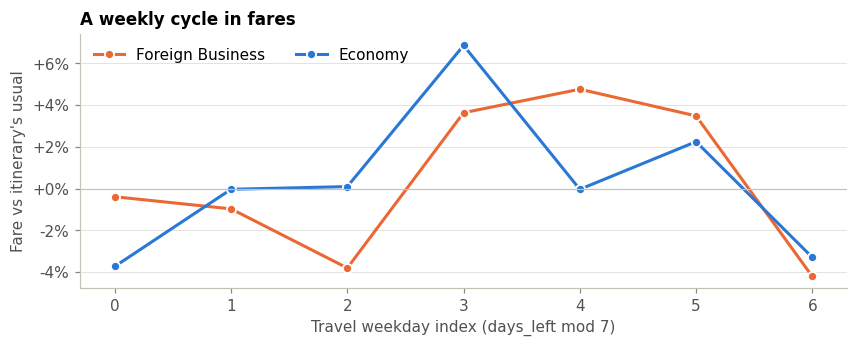

dow,0,1,2,3,4,5,6
Foreign Business,-0.4,-1.0,-3.8,3.6,4.8,3.5,-4.2
Economy,-3.7,-0.0,0.1,6.9,-0.0,2.2,-3.3


In [14]:
t = train.copy()
t["med"] = t.groupby("itin_c")["price"].transform("median")
t["n"] = t.groupby("itin_c")["price"].transform("size")
t = t[t["n"] >= 3].copy()
t["rel"] = t["price"] / t["med"] - 1              # fare relative to its itinerary's usual fare
t["lr"] = np.log(t["price"] / t["med"])
t["dow"] = (t["days_left"] % 7).astype(int)

fig, ax = plt.subplots(figsize=(9, 3.0))
weekly = {}
for seg, col in (("Foreign Business", ORANGE), ("Economy", BLUE)):
    s = t[t["segment"] == seg]
    curve = s.groupby("days_left")["rel"].mean().rolling(7, center=True, min_periods=1).mean()
    weekly[seg] = (s["rel"] - s["days_left"].map(curve)).groupby(s["dow"]).mean()   # booking curve removed
    ax.plot(weekly[seg].index, weekly[seg].values, color=col, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=1.2, label=seg)
ax.axhline(0, color=BASE, linewidth=0.8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("Travel weekday index (days_left mod 7)")
ax.set_ylabel("Fare vs itinerary's usual")
ax.grid(axis="y")
ax.legend(loc="upper left", ncol=2)
ax.set_title("A weekly cycle in fares")
plt.show()
display((100 * pd.DataFrame(weekly).T).round(1))

In [15]:
# itineraries that share a flight number move together on the same day
a = t[["flight", "flight_class", "itin_c", "days_left", "lr", "segment"]]
pairs = a.merge(a, on=["flight", "flight_class", "days_left"], suffixes=("", "_other"))
pairs = pairs[pairs["itin_c"] != pairs["itin_c_other"]]
for seg in ("Foreign Business", "Domestic Business", "Economy"):
    q = pairs[pairs["segment"] == seg]
    print(f"same flight, same day, other itinerary  [{seg:17s}]  pairs {len(q):5,d}   correlation {q['lr'].corr(q['lr_other']):.2f}")

# an airline's other flights on the same day (leave-one-out mean)
s = t.groupby(["airline_full", "flight_class", "days_left"])["lr"].agg(["sum", "count"]).reset_index()
b = t.merge(s, on=["airline_full", "flight_class", "days_left"])
b = b[b["count"] > 1]
b["loo"] = (b["sum"] - b["lr"]) / (b["count"] - 1)
for seg in ("Foreign Business", "Domestic Business", "Economy"):
    q = b[b["segment"] == seg]
    print(f"airline's other rows, same day          [{seg:17s}]  rows  {len(q):5,d}   correlation {q['lr'].corr(q['loo']):.2f}")

same flight, same day, other itinerary  [Foreign Business ]  pairs   968   correlation 0.40
same flight, same day, other itinerary  [Domestic Business]  pairs   510   correlation 0.29
same flight, same day, other itinerary  [Economy          ]  pairs    64   correlation 0.56
airline's other rows, same day          [Foreign Business ]  rows  1,327   correlation 0.30
airline's other rows, same day          [Domestic Business]  rows  4,311   correlation 0.34
airline's other rows, same day          [Economy          ]  rows  8,542   correlation 0.39


## 10. Duplicates and twins

In [16]:
RAW = ["airline", "flight", "source_city", "departure_time", "stops", "arrival_time",
       "destination_city", "flight_class", "duration", "days_left"]
print(f"exact duplicate training rows (all columns incl. price): {train.duplicated(subset=RAW + ['price']).sum()}")

TWIN = ITIN + ["flight_class", "days_left"]       # same itinerary, cabin and travel day
g = train.groupby(TWIN)["price"].agg(["size", "nunique"])
g = g[g["size"] > 1]
print(f"twin groups in train: {len(g)}, identical price in {(g['nunique'] == 1).mean():.0%} of them")
in_train = test.set_index(TWIN).index.isin(train.set_index(TWIN).index)
print(f"test rows with an exact twin in train: {in_train.sum()} ({in_train.mean():.1%})")

exact duplicate training rows (all columns incl. price): 279
twin groups in train: 655, identical price in 86% of them
test rows with an exact twin in train: 325 (8.3%)


## Summary

- `price` is two markets: Business averages about 6.8× Economy.
- `airline` and `duration` are ~20% missing but recoverable: the airline from the flight prefix, the duration from the itinerary.
- `days_left` hides a booking curve (Simpson's paradox) and acts as a travel date: a weekly cycle and same-day co-movement.
- Prices are fare buckets with random spikes; the noise floor is roughly 9,000–9,500 RMSE.
- Foreign-carrier Business (10% of rows) decides the score.
- 8% of test rows have an exact twin in train, usually with the identical price.

Next: **02_Preprocessing** turns these findings into features.